# Etapa 2 — Aprendizado Linear (regressão linear, Ridge e regressão logística)

**Como usar:** rode as células de cima para baixo. A tabela `dados/tabela_p4.csv` (a mesma das outras etapas) é procurada nas pastas vizinhas e, se não for achada, baixada do GitHub do grupo.

**O que é feito:**
1. Regressão para o valor da multa (em log) e classificação de `Multa_Alta`, a mesma pergunta da Etapa 1.
2. Regressão linear simples (fórmula fechada) e múltipla (fórmula fechada e gradiente descendente do zero).
3. Ridge (L2) com o λ escolhido por validação cruzada no treino, e gráfico dos coeficientes contra λ.
4. Regressão logística do zero (sigmoide e gradiente), comparada com o scikit-learn.

Sempre com semente 42.

In [1]:
%pip install numpy pandas matplotlib scikit-learn -q

In [2]:
import os, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, r2_score
from sklearn.model_selection import train_test_split, KFold

SEED = 42
np.random.seed(SEED)
plt.style.use('seaborn-v0_8-whitegrid')

URL_DADOS = "https://raw.githubusercontent.com/rafaellydosanjos/2o-Trab-SimbML-Incerteza_equipe_3/main/dados/"

def obter(nome='tabela_p4.csv'):
    """Procura a tabela em algumas pastas. Se não achar, baixa do GitHub do grupo."""
    for pasta in [Path.cwd(), Path.cwd() / 'dados', Path.cwd().parent / 'dados', Path('/content'), Path('/content/dados')]:
        if (pasta / nome).is_file():
            return str(pasta / nome)
    os.makedirs('dados', exist_ok=True)
    urllib.request.urlretrieve(URL_DADOS + nome, os.path.join('dados', nome))
    print('Baixado do GitHub:', nome)
    return os.path.join('dados', nome)

os.makedirs('figuras', exist_ok=True)
df = pd.read_csv(obter())
print('Autos na tabela:', len(df))

Baixado do GitHub: tabela_p4.csv
Autos na tabela: 2639


## Passo 1 — Alvos e atributos

- **Alvo contínuo:** `log(1 + valor da multa)`. O log é usado porque os valores vão de poucos reais a milhões, e a distribuição fica muito torta sem ele.
- **Alvo de classificação:** `Multa_Alta` (1 = multa acima da mediana de R$ 100.000), o mesmo da Etapa 1.
- **Atributos:** chuva, temperatura e umidade do mês (números), bioma, tipo de pessoa, tipo de ação e UF (categorias). A UF não estava na árvore da Etapa 1. Ela entra aqui porque melhora a regressão; para usar só os atributos da Etapa 1, troque `USAR_UF` para `False`.

Categorias com menos de 30 autos no treino são juntadas em `OUTRAS`, porque colunas quase sempre zero deixam o gradiente descendente muito lento. Para a regressão, valores zero e os 1% maiores multas do treino (limite calculado no treino) ficam de fora, porque multas de dezenas de milhões dominam o R². Para a logística, todos os autos entram. Os dados faltantes são preenchidos com a mediana (números) ou a moda (categorias) **calculadas só no treino**, para não vazar informação do teste. A separação é 80% treino e 20% teste, estratificada, semente 42.

In [3]:
USAR_UF = True

COLS_NUM = ['precip_mm', 'temp_media', 'umid_media']
COLS_CAT = ['BIOMA', 'TP_PESSOA_INFRATOR', 'TIPO_ACAO'] + (['UF'] if USAR_UF else [])

y_reg = np.log1p(df['VAL_AUTO_INFRACAO'].values.astype(float))
y_cls = df['Multa_Alta'].values.astype(int)

idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.2, random_state=SEED, stratify=y_cls)
tr, te = df.iloc[idx_tr].copy(), df.iloc[idx_te].copy()

for c in COLS_NUM:                                   # estatísticas só do treino
    mediana = tr[c].median()
    tr[c], te[c] = tr[c].fillna(mediana), te[c].fillna(mediana)
for c in COLS_CAT:
    moda = tr[c].mode()[0]
    tr[c], te[c] = tr[c].fillna(moda).astype(str), te[c].fillna(moda).astype(str)
    raras = tr[c].value_counts()[lambda v: v < 30].index          # categorias com menos de 30 autos no treino
    tr[c], te[c] = tr[c].where(~tr[c].isin(raras), 'OUTRAS'), te[c].where(~te[c].isin(raras), 'OUTRAS')

# As colunas 0/1 são criadas com treino e teste juntos (só os atributos, sem o alvo), para que as duas
# partes tenham exatamente as mesmas colunas e a mesma categoria de referência.
todos = pd.get_dummies(pd.concat([tr, te])[COLS_NUM + COLS_CAT], drop_first=True, dtype=float)
X_tr_df, X_te_df = todos.iloc[:len(tr)], todos.iloc[len(tr):]
nomes = list(X_tr_df.columns)

# Todas as colunas são padronizadas (média 0, desvio 1), o que ajuda o gradiente descendente a convergir.
media, desvio = X_tr_df.values.mean(axis=0), X_tr_df.values.std(axis=0)
desvio[desvio < 1e-8] = 1.0
X_train = (X_tr_df.values - media) / desvio
X_test = (X_te_df.values - media) / desvio
y_reg_train, y_reg_test = y_reg[idx_tr], y_reg[idx_te]
y_cls_train, y_cls_test = y_cls[idx_tr], y_cls[idx_te]

X_train_b = np.c_[np.ones(len(X_train)), X_train]    # coluna de 1s para o intercepto
X_test_b = np.c_[np.ones(len(X_test)), X_test]

def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - np.mean(y)) ** 2)

# Classificação (logística): usa todos os autos, como na Etapa 1.
XC_train_b, XC_test_b, XC_train, XC_test = X_train_b, X_test_b, X_train, X_test

# Regressão: tira valores zero e os 1% maiores (limite calculado só no treino). Multas de dezenas de milhões
# dominam o R² de poucos autos do teste, e o enunciado não pede para prever esses extremos.
val_tr, val_te = df['VAL_AUTO_INFRACAO'].values[idx_tr], df['VAL_AUTO_INFRACAO'].values[idx_te]
limite = np.quantile(val_tr, 0.99)
m_tr, m_te = (val_tr > 0) & (val_tr <= limite), (val_te > 0) & (val_te <= limite)
X_train, X_test, X_train_b, X_test_b = X_train[m_tr], X_test[m_te], X_train_b[m_tr], X_test_b[m_te]
y_reg_train, y_reg_test = y_reg_train[m_tr], y_reg_test[m_te]

print(f'Classificação: treino {len(XC_train)} | teste {len(XC_test)} | atributos {XC_train.shape[1]}')
print(f'Regressão (sem valor zero e sem o 1% maior, limite R$ {limite:,.0f}): treino {len(X_train)} | teste {len(X_test)}')

Classificação: treino 2111 | teste 528 | atributos 30
Regressão (sem valor zero e sem o 1% maior, limite R$ 10,059,080): treino 2089 | teste 523


## Passo 2 — Regressão linear simples (fórmula fechada)

Para um atributo $x$: $w_1 = \dfrac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}$ e $w_0 = \bar y - w_1\bar x$.

O atributo é o que tem **maior correlação (em módulo) com o alvo no treino**.

Atributo escolhido: UF_PA (|correlação| = 0.340)
R² simples, do zero: 0.0441 | scikit-learn: 0.0441


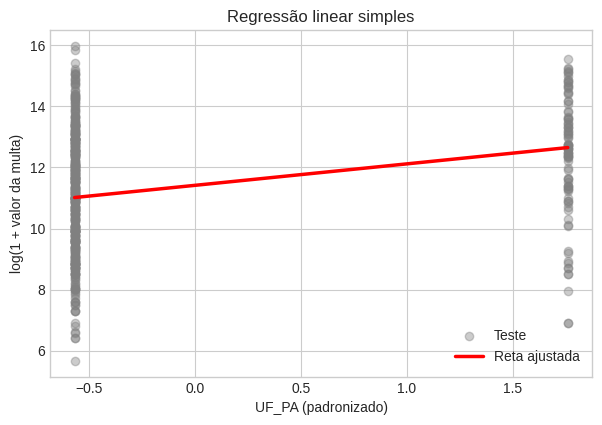

In [4]:
def regressao_simples(x, y):
    xb, yb = x.mean(), y.mean()
    w1 = np.sum((x - xb) * (y - yb)) / np.sum((x - xb) ** 2)
    return yb - w1 * xb, w1

corr = [abs(np.corrcoef(X_train[:, j], y_reg_train)[0, 1]) for j in range(X_train.shape[1])]
j = int(np.argmax(corr))
w0, w1 = regressao_simples(X_train[:, j], y_reg_train)
pred = w0 + w1 * X_test[:, j]
r2_simples = r2(y_reg_test, pred)

sk = LinearRegression().fit(X_train[:, [j]], y_reg_train)
r2_simples_sk = sk.score(X_test[:, [j]], y_reg_test)
print(f'Atributo escolhido: {nomes[j]} (|correlação| = {corr[j]:.3f})')
print(f'R² simples, do zero: {r2_simples:.4f} | scikit-learn: {r2_simples_sk:.4f}')

ordem = np.argsort(X_test[:, j])
plt.figure(figsize=(7, 4.5))
plt.scatter(X_test[:, j], y_reg_test, alpha=0.4, color='gray', label='Teste')
plt.plot(X_test[ordem, j], pred[ordem], color='red', linewidth=2.5, label='Reta ajustada')
plt.xlabel(f'{nomes[j]} (padronizado)'); plt.ylabel('log(1 + valor da multa)')
plt.title('Regressão linear simples'); plt.legend()
plt.savefig('figuras/regressao_simples.png', dpi=200, bbox_inches='tight'); plt.show()

## Passo 3 — Regressão múltipla: fórmula fechada e gradiente descendente

Fórmula fechada (equações normais): $w = (X^TX)^{-1}X^Ty$.

Gradiente descendente do zero (como no enunciado): $w \leftarrow w - \alpha\,\frac{1}{N}X^T(Xw-y)$. Os dois devem chegar aos mesmos pesos.

R² múltipla, fórmula fechada: 0.3918
R² múltipla, gradiente descendente: 0.3918
R² múltipla, scikit-learn: 0.3918
Maior diferença entre os pesos (GD x fechada): 0.0


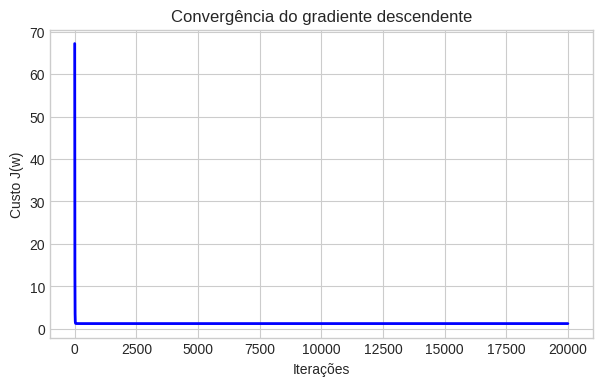

In [5]:
def multipla_fechada(X, y):
    return np.linalg.pinv(X.T @ X) @ X.T @ y

def gradiente_descendente(X, y, alpha=0.1, num_iter=20000):
    N, d = X.shape
    w = np.zeros(d)
    custo = []
    for _ in range(num_iter):
        erro = X @ w - y
        custo.append(np.sum(erro ** 2) / (2 * N))
        w = w - alpha * (X.T @ erro) / N
    return w, custo

w_fechada = multipla_fechada(X_train_b, y_reg_train)
w_gd, custo = gradiente_descendente(X_train_b, y_reg_train)

r2_fechada = r2(y_reg_test, X_test_b @ w_fechada)
r2_gd = r2(y_reg_test, X_test_b @ w_gd)
sk_multi = LinearRegression().fit(X_train, y_reg_train)
r2_multi_sk = sk_multi.score(X_test, y_reg_test)

print(f'R² múltipla, fórmula fechada: {r2_fechada:.4f}')
print(f'R² múltipla, gradiente descendente: {r2_gd:.4f}')
print(f'R² múltipla, scikit-learn: {r2_multi_sk:.4f}')
print('Maior diferença entre os pesos (GD x fechada):', np.abs(w_gd - w_fechada).max().round(6))

plt.figure(figsize=(7, 4))
plt.plot(custo, color='blue', linewidth=2)
plt.xlabel('Iterações'); plt.ylabel('Custo J(w)'); plt.title('Convergência do gradiente descendente')
plt.savefig('figuras/curva_custo.png', dpi=200, bbox_inches='tight'); plt.show()

## Passo 4 — Ridge (L2) e curva dos coeficientes contra λ

Ridge: $w = (X^TX + \lambda I)^{-1}X^Ty$, sem penalizar o intercepto. O λ é escolhido por **validação cruzada de 5 partes no treino** (o teste não é usado para escolher). Depois o R² é medido no teste.

λ ótimo (validação cruzada no treino): 24.2446
R² Ridge no teste, do zero: 0.3917 | scikit-learn: 0.3917


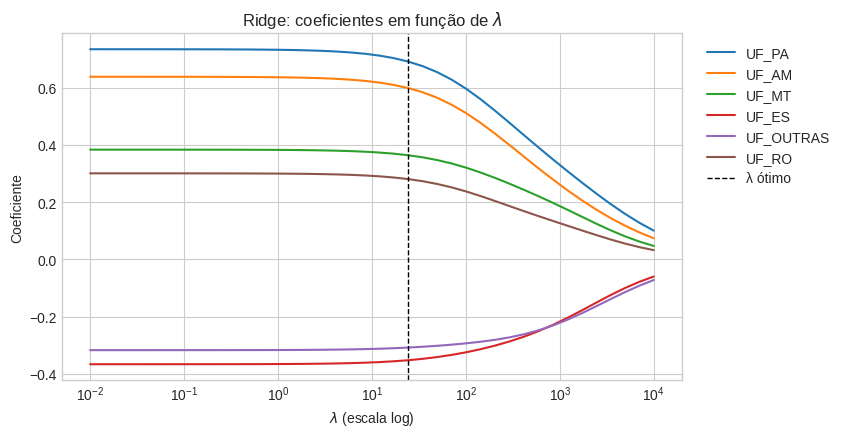

In [6]:
def ridge(X, y, lmbda):
    I = np.eye(X.shape[1]); I[0, 0] = 0                 # intercepto não é penalizado
    return np.linalg.pinv(X.T @ X + lmbda * I) @ X.T @ y

lambdas = np.logspace(-2, 4, 40)
r2_cv = []
for lmb in lambdas:
    notas = []
    for i_fit, i_val in KFold(5, shuffle=True, random_state=SEED).split(X_train_b):
        w = ridge(X_train_b[i_fit], y_reg_train[i_fit], lmb)
        notas.append(r2(y_reg_train[i_val], X_train_b[i_val] @ w))
    r2_cv.append(np.mean(notas))
lambda_otimo = lambdas[int(np.argmax(r2_cv))]

w_ridge = ridge(X_train_b, y_reg_train, lambda_otimo)
r2_ridge = r2(y_reg_test, X_test_b @ w_ridge)
r2_ridge_sk = Ridge(alpha=lambda_otimo).fit(X_train, y_reg_train).score(X_test, y_reg_test)
print(f'λ ótimo (validação cruzada no treino): {lambda_otimo:.4f}')
print(f'R² Ridge no teste, do zero: {r2_ridge:.4f} | scikit-learn: {r2_ridge_sk:.4f}')

coefs = np.array([ridge(X_train_b, y_reg_train, lmb)[1:] for lmb in lambdas])
maiores = np.argsort(-np.abs(w_fechada[1:]))[:6]        # os 6 coeficientes maiores
plt.figure(figsize=(8, 4.5))
for k in maiores:
    plt.plot(lambdas, coefs[:, k], label=nomes[k])
plt.axvline(lambda_otimo, color='black', linestyle='--', linewidth=1, label='λ ótimo')
plt.xscale('log'); plt.xlabel(r'$\lambda$ (escala log)'); plt.ylabel('Coeficiente')
plt.title(r'Ridge: coeficientes em função de $\lambda$')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.savefig('figuras/ridge_coeficientes.png', dpi=200, bbox_inches='tight'); plt.show()

## Passo 5 — Regressão logística do zero (problema da Etapa 1)

Probabilidade: $P(y=1\mid x)=\sigma(w^Tx)$, com $\sigma(z)=1/(1+e^{-z})$. O gradiente da perda é $\frac{1}{N}X^T(\sigma(Xw)-y)$. A classe prevista é 1 quando a probabilidade passa de 0,5. A acurácia do teste é comparada com a de sempre prever a classe mais comum.

In [7]:
def sigmoide(z):
    return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

def logistica_fit(X, y, alpha=0.1, num_iter=10000):
    w = np.zeros(X.shape[1])
    for _ in range(num_iter):
        w = w - alpha * (X.T @ (sigmoide(X @ w) - y)) / len(y)
    return w

w_log = logistica_fit(XC_train_b, y_cls_train)
pred_log = (sigmoide(XC_test_b @ w_log) >= 0.5).astype(int)
acc_log = accuracy_score(y_cls_test, pred_log)
acc_log_sk = LogisticRegression(max_iter=2000).fit(XC_train, y_cls_train).score(XC_test, y_cls_test)
base = max(y_cls_test.mean(), 1 - y_cls_test.mean())
print(f'Acurácia da logística, do zero: {acc_log:.2%} | scikit-learn: {acc_log_sk:.2%}')
print(f'Acurácia de sempre prever a classe mais comum: {base:.2%}')

Acurácia da logística, do zero: 77.08% | scikit-learn: 77.08%
Acurácia de sempre prever a classe mais comum: 50.19%


## Passo 6 — Tabela final

In [8]:
tabela = pd.DataFrame({
    'Modelo': ['Regressão linear simples', 'Regressão múltipla (fórmula fechada)', 'Regressão múltipla (gradiente descendente)',
               'Ridge (L2, λ ótimo)', 'Regressão logística'],
    'Esperado': ['R² 0,55–0,65', 'R² 0,70–0,80', 'R² 0,70–0,80', 'R² 0,72–0,82', '78–85%'],
    'Do zero': [f'{r2_simples:.4f}', f'{r2_fechada:.4f}', f'{r2_gd:.4f}', f'{r2_ridge:.4f}', f'{acc_log:.2%}'],
    'scikit-learn': [f'{r2_simples_sk:.4f}', f'{r2_multi_sk:.4f}', '—', f'{r2_ridge_sk:.4f}', f'{acc_log_sk:.2%}'],
})
print(tabela.to_string(index=False))

                                    Modelo     Esperado Do zero scikit-learn
                  Regressão linear simples R² 0,55–0,65  0.0441       0.0441
      Regressão múltipla (fórmula fechada) R² 0,70–0,80  0.3918       0.3918
Regressão múltipla (gradiente descendente) R² 0,70–0,80  0.3918            —
                       Ridge (L2, λ ótimo) R² 0,72–0,82  0.3917       0.3917
                       Regressão logística       78–85%  77.08%       77.08%
